# Cafe Sales Data Analysis

## 1. Introduction

### Project Overview

This project focuses on exploring and analysing cafe sales data using Python. The objective is to understand sales patterns, product performance, customer purchasing behaviour, and payment preferences through Exploratory Data Analysis (EDA).

### Objectives

- Analyse overall sales and revenue patterns.
- Identify the best-performing products based on sales volume and revenue.
- Examine purchasing behaviour across different payment methods.
- Explore sales performance across different service types.
- Identify meaningful patterns and business insights from the dataset.

### Tools & Technologies

- Python
- Pandas
- NumPy
- Jupyter Notebook
- Matplotlib

### Analysis Approach

The project follows a structured EDA approach, including data inspection, descriptive statistics, univariate analysis, and category-based analysis. The findings are supported by data and visualisations.

In [107]:
import pandas as pd

In [108]:
import numpy as np

In [109]:
import matplotlib.pyplot as plt

In [110]:
from pathlib import Path
data_dir = Path("../data")
eda_df = pd.read_csv(data_dir / "cafe_sales_cleaned.csv")

# cleaned_file = next(
#     (parent / "data" / "cafe_sales_cleaned.csv"
#      for parent in (Path.cwd(), *Path.cwd().parents)
#      if (parent / "data" / "cafe_sales_cleaned.csv").is_file()),
#     None,
# )
# if cleaned_file is None:
#     raise FileNotFoundError(f"Could not find data/cafe_sales_cleaned.csv from {Path.cwd()}")

# eda_df = pd.read_csv(cleaned_file)

In [111]:
eda_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9974 entries, 0 to 9973
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Transaction ID     9974 non-null   str    
 1   Item               9974 non-null   str    
 2   Quantity           9974 non-null   float64
 3   Price Per Unit     9974 non-null   float64
 4   Total Spent        9974 non-null   float64
 5   Payment Method     9974 non-null   str    
 6   Location           9974 non-null   str    
 7   Transaction Date   9514 non-null   str    
 8   Day of the Week    9514 non-null   str    
 9   Transaction Month  9514 non-null   str    
dtypes: float64(3), str(7)
memory usage: 779.3 KB


In [112]:
eda_df.describe()

,Quantity,Price Per Unit,Total Spent
count,9974.000000,9974.000000,9974.000000
mean,3.024865,2.946962,8.927411
std,1.420504,1.280144,6.002644
min,1.000000,1.000000,1.000000
25%,2.000000,2.000000,4.000000
50%,3.000000,3.000000,8.000000
75%,4.000000,4.000000,12.000000
max,5.000000,5.000000,25.000000


In [113]:
eda_df.shape

(9974, 10)

In [114]:
eda_df.dtypes

Transaction ID           str
Item                     str
Quantity             float64
Price Per Unit       float64
Total Spent          float64
Payment Method           str
Location                 str
Transaction Date         str
Day of the Week          str
Transaction Month        str
dtype: object

In [115]:
eda_df.head(10)

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date,Day of the Week,Transaction Month
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,2023-09-08,Friday,September
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In-store,2023-05-16,Tuesday,May
2,TXN_4271903,Cookie,4.0,1.0,4.0,Credit Card,In-store,2023-07-19,Wednesday,July
3,TXN_7034554,Salad,2.0,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27,Thursday,April
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In-store,2023-06-11,Sunday,June
5,TXN_2602893,Smoothie,5.0,4.0,20.0,Credit Card,UNKNOWN,2023-03-31,Friday,March
6,TXN_4433211,UNKNOWN,3.0,3.0,9.0,UNKNOWN,Takeaway,2023-10-06,Friday,October
7,TXN_6699534,Sandwich,4.0,4.0,16.0,Cash,UNKNOWN,2023-10-28,Saturday,October
8,TXN_4717867,UNKNOWN,5.0,3.0,15.0,UNKNOWN,Takeaway,2023-07-28,Friday,July
9,TXN_2064365,Sandwich,5.0,4.0,20.0,UNKNOWN,In-store,2023-12-31,Sunday,December


In [116]:
eda_df.tail(10)

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date,Day of the Week,Transaction Month
9964,TXN_1538510,Coffee,5.0,2.0,10.0,Digital Wallet,UNKNOWN,2023-05-22,Monday,May
9965,TXN_3897619,Sandwich,3.0,4.0,12.0,Cash,Takeaway,2023-02-24,Friday,February
9966,TXN_2739140,Smoothie,4.0,4.0,16.0,UNKNOWN,In-store,2023-07-05,Wednesday,July
9967,TXN_4766549,Smoothie,2.0,4.0,8.0,Cash,UNKNOWN,2023-10-20,Friday,October
9968,TXN_7851634,UNKNOWN,4.0,4.0,16.0,UNKNOWN,UNKNOWN,2023-01-08,Sunday,January
9969,TXN_7672686,Coffee,2.0,2.0,4.0,UNKNOWN,UNKNOWN,2023-08-30,Wednesday,August
9970,TXN_9659401,Cookie,3.0,1.0,3.0,Digital Wallet,UNKNOWN,2023-06-02,Friday,June
9971,TXN_5255387,Coffee,4.0,2.0,8.0,Digital Wallet,UNKNOWN,2023-03-02,Thursday,March
9972,TXN_7695629,Cookie,3.0,1.0,3.0,Digital Wallet,UNKNOWN,2023-12-02,Saturday,December
9973,TXN_6170729,Sandwich,3.0,4.0,12.0,Cash,In-store,2023-11-07,Tuesday,November


## 2. Product Analysis


**Question:** Which product has the highest total quantity sold?


In [117]:
item_quantity = eda_df[eda_df['Item'] != 'UNKNOWN'].groupby('Item')['Quantity'].sum().sort_values(ascending = False)
item_quantity 

Item
Coffee      3904.0
Salad       3819.0
Tea         3650.0
Cookie      3598.0
Juice       3505.0
Cake        3468.0
Sandwich    3429.0
Smoothie    3336.0
Name: Quantity, dtype: float64

Coffee was the highest-selling product, with a total of 3,904 units sold, followed by Salad with 3,819 units. Smoothie recorded the lowest sales quantity, with 3,336 units. Overall, Coffee was the most popular product in terms of total quantity sold.

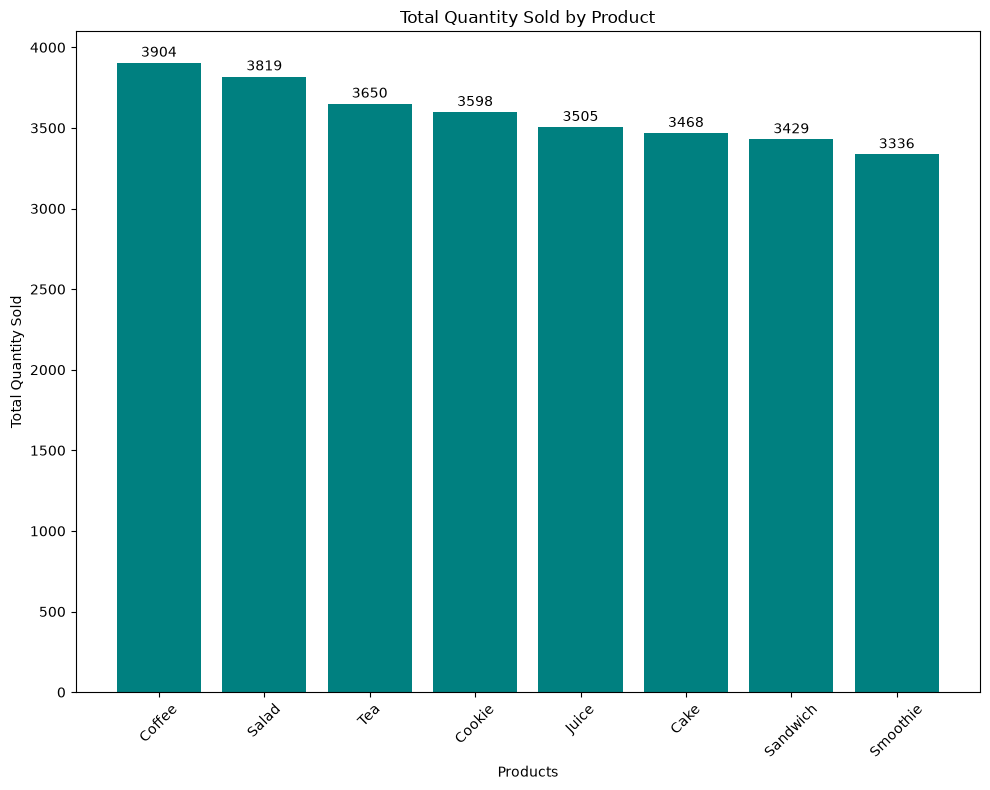

In [118]:
plt.figure(figsize = (10,8))
bars = plt.bar(item_quantity.index, item_quantity.values ,color = 'teal')
ax = plt.gca()
ax.bar_label(bars,fmt="%.0f",padding= 2) 
plt.xlabel('Products')
plt.ylabel('Total Quantity Sold')
plt.title('Total Quantity Sold by Product') 
plt.xticks(rotation=45)
plt.tight_layout()
plt.show() 

#plt.ylim(0,item_quantity.max() + 5)

**Question:** How many transactions include each product?


In [119]:
total_transaction = eda_df[eda_df['Item'] != 'UNKNOWN'].groupby('Item')['Transaction ID'].count().sort_values(ascending=False)
total_transaction

Item
Coffee      1286
Salad       1270
Cookie      1211
Tea         1206
Juice       1168
Cake        1138
Sandwich    1127
Smoothie    1094
Name: Transaction ID, dtype: int64

**Finding 1 — Product Transaction Frequency**

Coffee recorded the highest number of transactions (1,286), followed by Salad (1,270). Smoothie had the lowest transaction count, with 1,094 transactions. This indicates that Coffee appeared in the highest number of customer transactions among the known products.

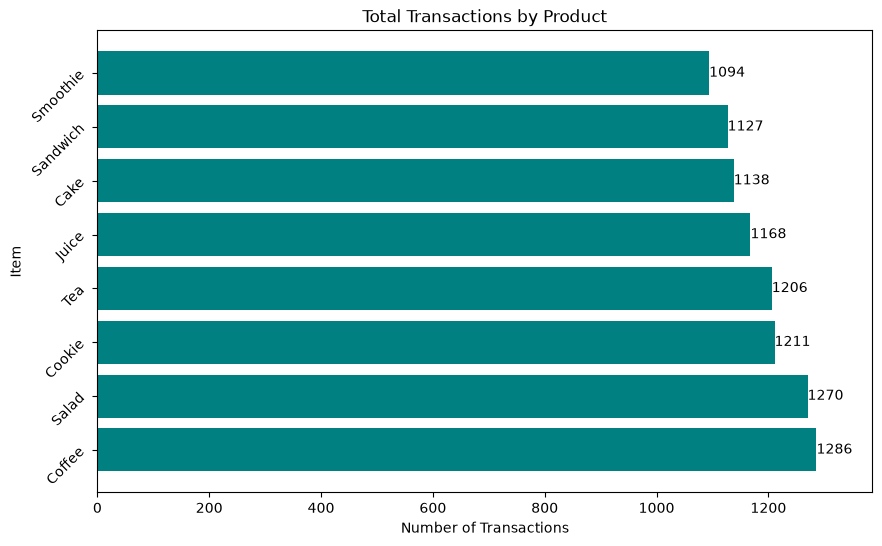

In [120]:
plt.figure(figsize = (10,6))
bars = plt.barh(total_transaction.index,total_transaction.values,color = 'teal')  
plt.title('Total Transactions by Product')
plt.xlabel('Number of Transactions')
plt.ylabel('Item')
ax = plt.gca()
ax.bar_label(bars) 
plt.xlim(0, total_transaction.max() + 100) 
plt.yticks(rotation = 45)
plt.show()

**Question:** What is the average transaction spending for each product?


In [121]:
avg_spending_product = eda_df[eda_df['Item'] != 'UNKNOWN'].groupby('Item')['Total Spent'].mean().sort_values(ascending=False) 
avg_spending_product

Item
Salad       15.035433
Smoothie    12.197441
Sandwich    12.170364
Cake         9.142355
Juice        9.002568
Coffee       6.071540
Tea          4.539801
Cookie       2.971098
Name: Total Spent, dtype: float64

Salad recorded the highest average transaction spending at ₹15.04, followed by Smoothie at ₹12.20 and Sandwich at ₹12.17. Cookie had the lowest average transaction spending at ₹2.97.

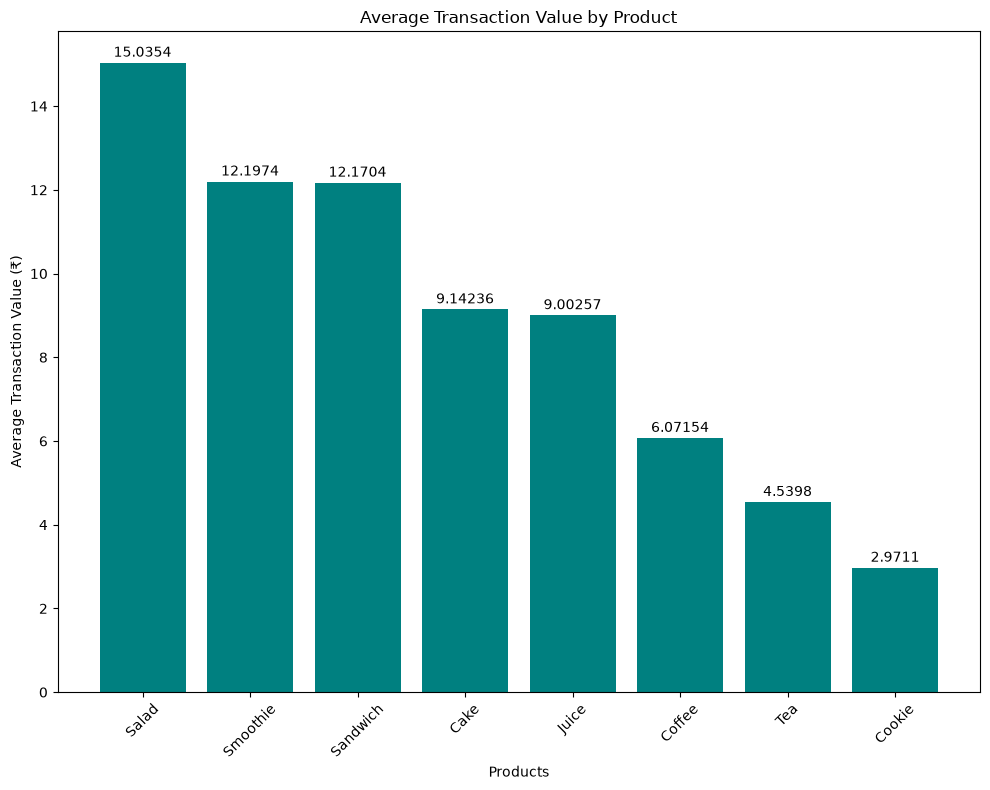

In [122]:
plt.figure(figsize = (10,8))
bars = plt.bar(avg_spending_product.index,avg_spending_product.values ,color = 'teal')
ax = plt.gca()
ax.bar_label(bars,padding= 2) 
plt.xlabel('Products')
plt.ylabel('Average Transaction Value (₹)')
plt.title('Average Transaction Value by Product') 
plt.xticks(rotation=45)
plt.tight_layout()
plt.show() 


**Question:** What is the average selling price of each product?


In [123]:
avg_selling_price = eda_df[eda_df['Item'] != 'UNKNOWN'].groupby('Item')['Price Per Unit'].mean().sort_values(ascending=False)
avg_selling_price

Item
Salad       5.0
Sandwich    4.0
Smoothie    4.0
Cake        3.0
Juice       3.0
Coffee      2.0
Tea         1.5
Cookie      1.0
Name: Price Per Unit, dtype: float64

**Finding 2 — Average Spending and Unit Price by Product**

Salad had the highest average transaction spending (₹15.04) and the highest average selling price (₹5.00) among the known products. Cookie had the lowest average transaction spending (₹2.97) and the lowest average selling price (₹1.00).


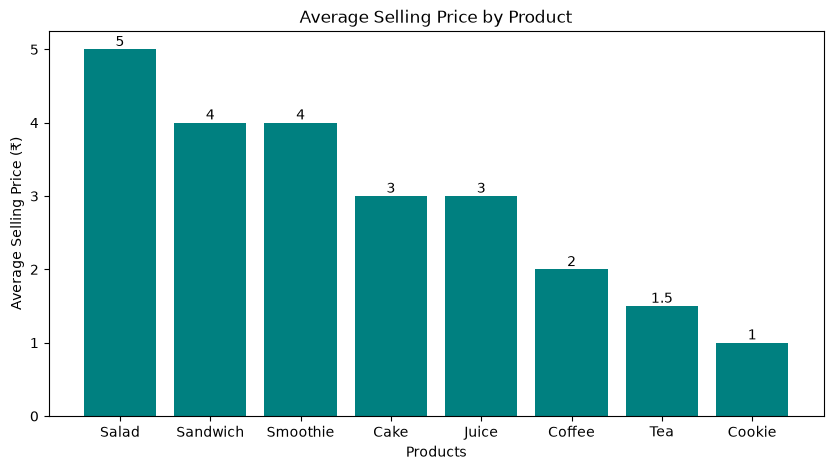

In [124]:
plt.figure(figsize = (10,5))
bars = plt.bar(avg_selling_price.index, avg_selling_price.values, color = 'teal') 
ax = plt.gca()
ax.bar_label(bars) 
plt.xlabel('Products')
plt.ylabel('Average Selling Price (₹)')
plt.title('Average Selling Price by Product')
plt.show()

## 3. Payment Method Analysis

### Business Questions
1. Which payment method generates the highest total revenue?
2. Which payment method has the highest number of transactions?
3. Which payment method has the highest average transaction value?
4. Does purchase quantity differ across payment methods?


In [125]:
payment_avg_value = eda_df[eda_df['Payment Method'] != 'UNKNOWN'].groupby('Payment Method')['Total Spent'].mean().sort_values(ascending=False) 
payment_avg_value 

Payment Method
Cash              9.051686
Credit Card       9.014991
Digital Wallet    8.933888
Name: Total Spent, dtype: float64

Cash recorded the highest average transaction value at ₹9.05, followed closely by Credit Card at ₹9.01. Digital Wallet had the lowest average transaction value at ₹8.93.

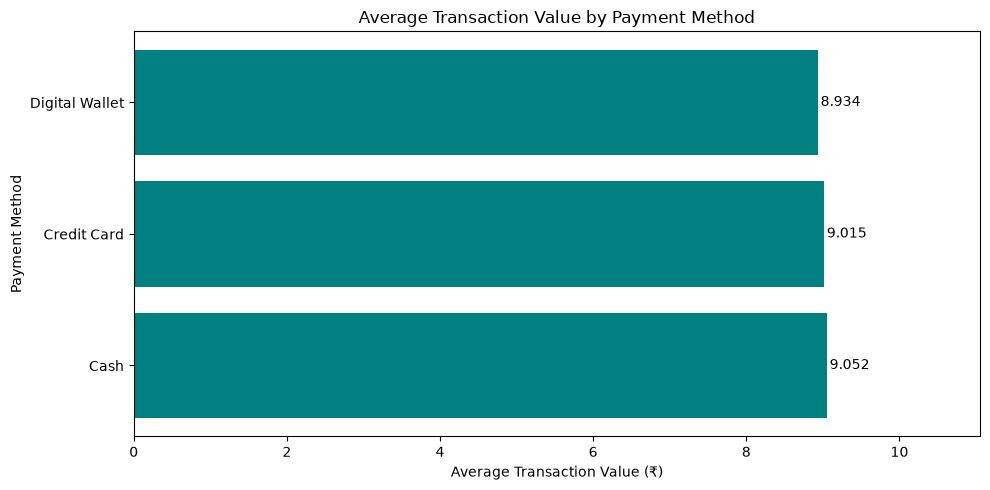

In [126]:
plt.figure(figsize = (10,5))
bars = plt.barh(payment_avg_value.index, payment_avg_value.values, color = 'teal') 
ax = plt.gca()
ax.bar_label(bars, padding = 2,fmt="%.3f") 
plt.xlim(0, payment_avg_value .max() + 2) 
plt.xlabel('Average Transaction Value (₹)')
plt.ylabel('Payment Method')
plt.title('Average Transaction Value by Payment Method') 
plt.tight_layout() 
plt.show()

Question: How do total revenue and the number of transactions vary across different payment methods?

Total Revenue

In [127]:
payment_revenue = eda_df[eda_df['Payment Method'] != 'UNKNOWN'].groupby("Payment Method")['Total Spent'].sum().sort_values(ascending=False) 
payment_revenue


Payment Method
Credit Card       20446.0
Digital Wallet    20405.0
Cash              20402.5
Name: Total Spent, dtype: float64

Credit Card generated the highest total revenue of ₹20,446, followed closely by Digital Wallet at ₹20,405. Cash recorded the lowest total revenue at ₹20,402.50.

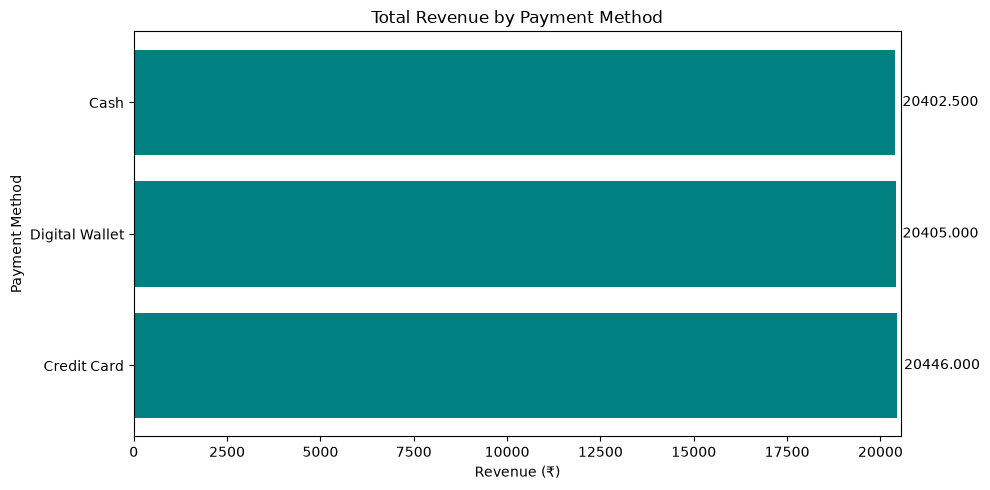

In [128]:
plt.figure(figsize = (10,5))
bars = plt.barh(payment_revenue.index, payment_revenue.values, color = 'teal') 
ax = plt.gca()
ax.bar_label(bars, padding = 5,fmt="%.3f") 
plt.xlim(0, payment_revenue .max() + 100) 
plt.xlabel('Revenue (₹)')
plt.ylabel('Payment Method')
plt.title('Total Revenue by Payment Method') 
plt.tight_layout() 
plt.show()

Number of transactions

In [129]:
totaltansaction_paymentmethod = eda_df[eda_df['Payment Method'] != 'UNKNOWN'].groupby("Payment Method")['Total Spent'].count().sort_values(ascending=False)
totaltansaction_paymentmethod

Payment Method
Digital Wallet    2284
Credit Card       2268
Cash              2254
Name: Total Spent, dtype: int64

Credit Card generated the highest total revenue (₹20,446), while Digital Wallet recorded the highest number of transactions (2,284). Cash had the highest average transaction value (₹9.05). However, the revenue difference across all three payment methods was negligible.

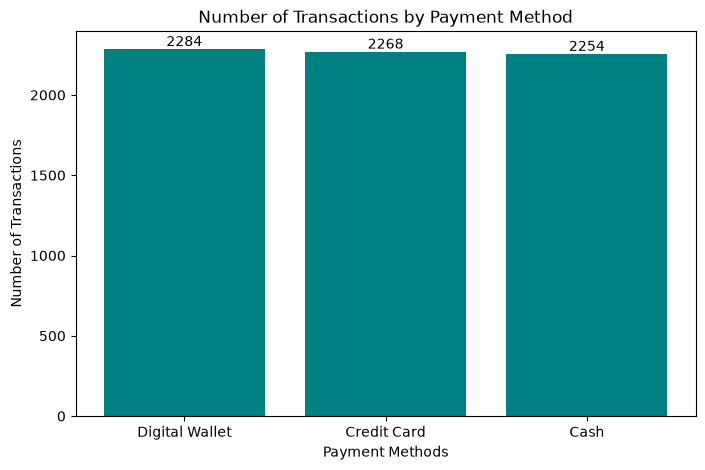

In [130]:
plt.figure(figsize = (8,5))
bars = plt.bar(totaltansaction_paymentmethod.index, totaltansaction_paymentmethod.values,color = 'teal')
plt.bar_label(bars) 
plt.title('Number of Transactions by Payment Method')
plt.xlabel('Payment Methods')
plt.ylabel('Number of Transactions')
plt.show()


How does the purchase quantity distribution vary across different payment methods?

In [131]:
payment_quantity= eda_df[eda_df['Payment Method'] != 'UNKNOWN'].groupby("Payment Method")['Quantity'].mean().sort_values(ascending=False) 
payment_quantity

Payment Method
Digital Wallet    3.035464
Cash              3.035049
Credit Card       3.018519
Name: Quantity, dtype: float64

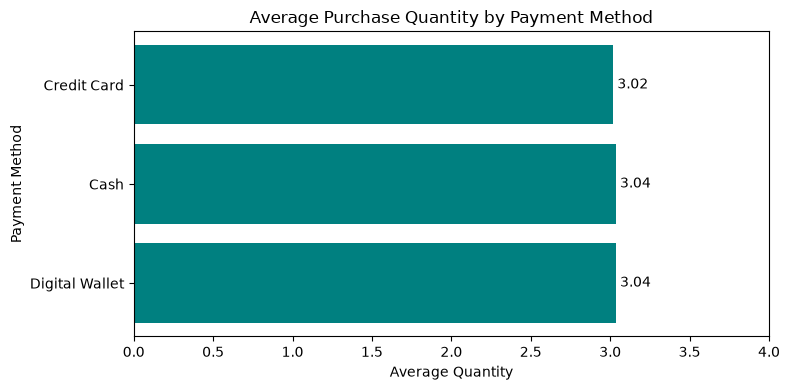

In [132]:
plt.figure(figsize=(8, 4))

bars = plt.barh(payment_quantity.index, payment_quantity.values, color='teal')

plt.bar_label(bars, fmt='%.2f', padding=3)

plt.xlabel('Average Quantity')
plt.ylabel('Payment Method')
plt.title('Average Purchase Quantity by Payment Method')
plt.xlim(0, 4)
plt.tight_layout()
plt.show()

In [133]:
payment_quantity_median = eda_df[eda_df['Payment Method'] != 'UNKNOWN'].groupby("Payment Method")['Quantity'].median().sort_values(ascending=False) 
payment_quantity_median

Payment Method
Cash              3.0
Credit Card       3.0
Digital Wallet    3.0
Name: Quantity, dtype: float64

The average purchase quantity remains nearly consistent across all payment methods, while the median quantity is 3 for every payment method. This indicates that customers tend to purchase similar quantities regardless of their chosen payment method.

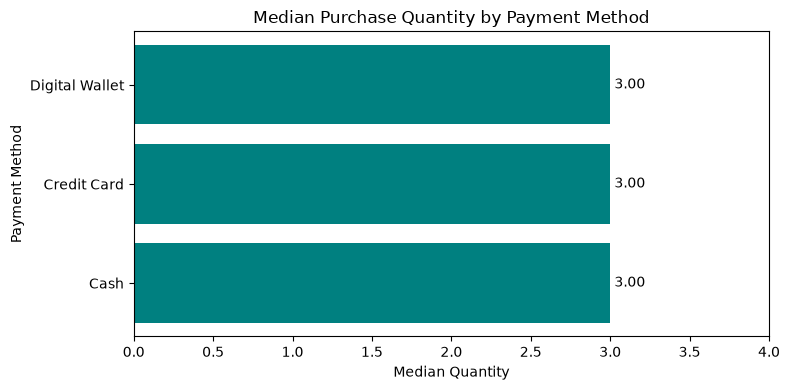

In [134]:
plt.figure(figsize=(8, 4))

bars = plt.barh(payment_quantity_median.index, payment_quantity_median.values, color='teal')

plt.bar_label(bars, fmt='%.2f', padding=3)

plt.xlabel('Median Quantity')
plt.ylabel('Payment Method')
plt.title('Median Purchase Quantity by Payment Method')
plt.xlim(0, 4)
plt.tight_layout()
plt.show()

## 4. Univariate Analysis

### 4.1 Transaction Amount Distribution

**Question:** How are transaction amounts distributed across cafe transactions?


In [135]:
eda_df['Total Spent'].describe()

count    9974.000000
mean        8.927411
std         6.002644
min         1.000000
25%         4.000000
50%         8.000000
75%        12.000000
max        25.000000
Name: Total Spent, dtype: float64

**Finding:**

The cafe recorded 9,974 transactions, with an average transaction value of ₹8.93 and a median of ₹8. Transaction amounts ranged from ₹1 to ₹25. The first quartile (Q1) was ₹4, while the third quartile (Q3) was ₹12, indicating that 50% of transactions were between ₹4 and ₹12.

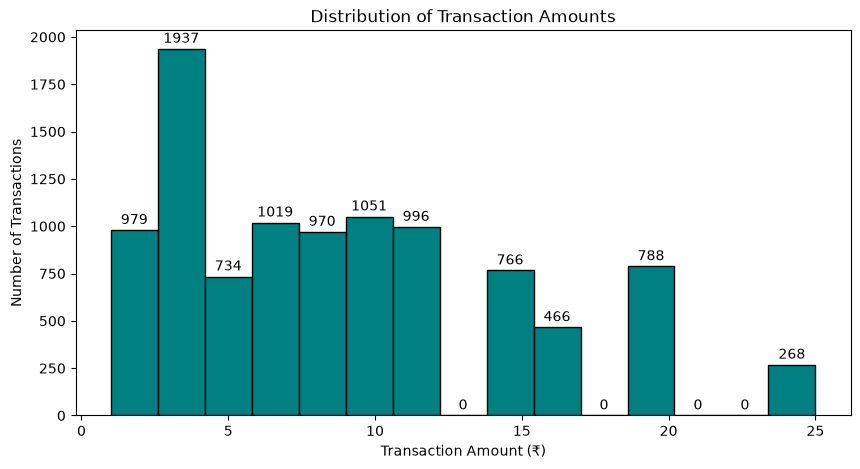

In [136]:
plt.figure(figsize=(10,5))

counts, bins, patches = plt.hist(
    eda_df['Total Spent'],
    bins=15,
    color='teal',
    edgecolor='black'
)

plt.bar_label(patches, padding=2, fmt='%.0f')

plt.xlabel('Transaction Amount (₹)')
plt.ylabel('Number of Transactions')
plt.title('Distribution of Transaction Amounts')

plt.show()

In [137]:
total_count = eda_df['Total Spent'].value_counts().sort_index()
total_count

Total Spent
1.0      249
1.5      212
2.0      518
3.0      968
4.0      969
4.5      238
5.0      496
6.0     1019
7.5      250
8.0      720
9.0      509
10.0     542
12.0     996
15.0     766
16.0     466
20.0     788
25.0     268
Name: count, dtype: int64

The most frequent transaction amount was ₹6, recorded in 1,019 transactions, followed by ₹12 with 996 transactions. This indicates that ₹6 was the most commonly occurring transaction value in the dataset.

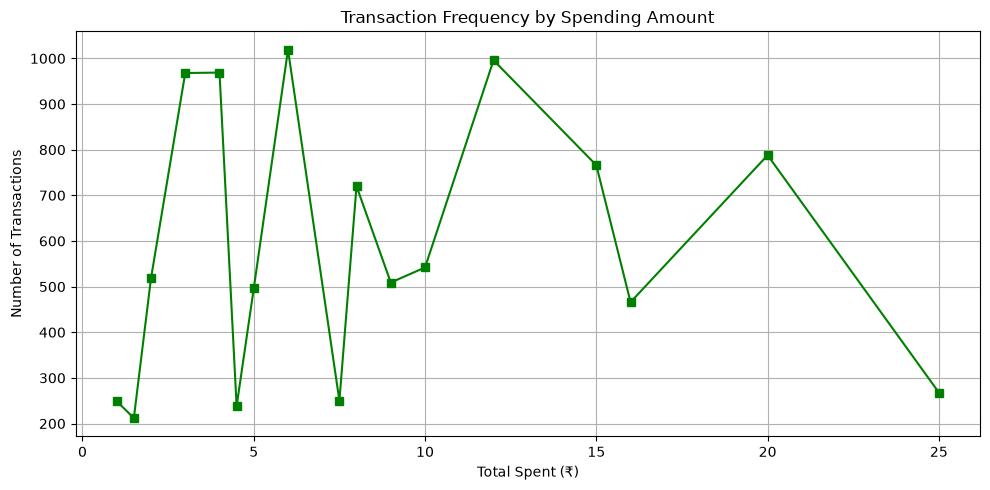

In [177]:
plt.figure(figsize=(10,5))

bars = plt.plot(total_count.index, total_count.values, color='green', marker = 's')
plt.xlabel('Total Spent (₹)')
plt.ylabel('Number of Transactions')
plt.title('Transaction Frequency by Spending Amount')
plt.grid()
plt.tight_layout()
plt.show()

### 4.2 Quantity Distribution

**Question:** How is the quantity of items distributed across cafe transactions?

#### 4.2.1 Categorical Distribution

In [139]:
eda_df[eda_df['Item'] != 'UNKNOWN']['Quantity'].describe()

count    9500.000000
mean        3.022000
std         1.421875
min         1.000000
25%         2.000000
50%         3.000000
75%         4.000000
max         5.000000
Name: Quantity, dtype: float64

In [140]:
eda_df[eda_df['Item'] != 'UNKNOWN']['Quantity'].mode()

0    5.0
Name: Quantity, dtype: float64

In [141]:
quantity_count = eda_df[eda_df['Item'] != 'UNKNOWN']['Quantity'].value_counts().sort_index() 
quantity_count

Quantity
1.0    1844
2.0    1962
3.0    1841
4.0    1847
5.0    2006
Name: count, dtype: int64

The most frequently purchased quantity was 5 units, recorded in 2,006 transactions, while 3 units was the least frequent, appearing in 1,841 transactions. The median quantity was 3 units and the average was approximately 3.02 units.

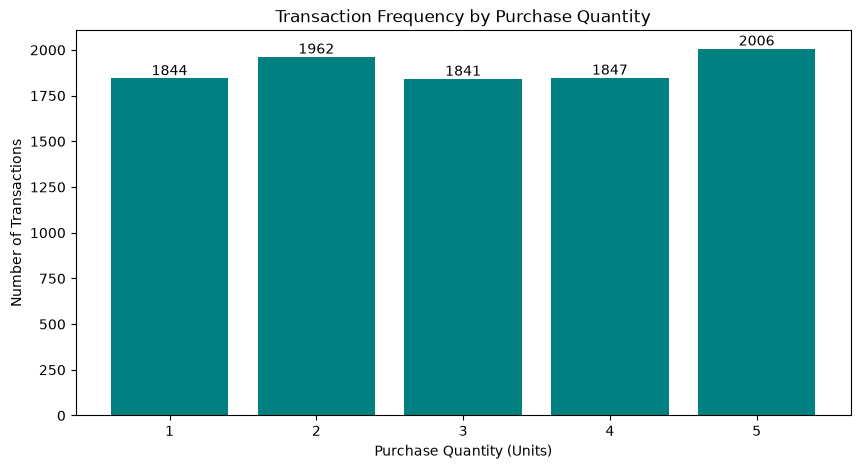

In [142]:
plt.figure(figsize=(10,5))

bars = plt.bar(quantity_count.index, quantity_count.values, color='teal')

plt.bar_label(bars)
plt.xlabel('Purchase Quantity (Units)')
plt.ylabel('Number of Transactions')
plt.title('Transaction Frequency by Purchase Quantity')

plt.show()

##### 4.3.1 Weekly Transaction Distribution

Question: Which day of the week has the highest number of cafe transactions?

In [143]:
day_weeks = eda_df['Day of the Week'].value_counts().sort_values(ascending=False)
day_weeks

Day of the Week
Friday       1383
Monday       1379
Sunday       1378
Thursday     1376
Saturday     1352
Wednesday    1338
Tuesday      1308
Name: count, dtype: int64

**Finding: Weekly Transaction Distribution**

Friday recorded the highest number of transactions (1,383), while Tuesday recorded the lowest (1,308). However, transaction counts were relatively evenly distributed across the seven days, with a difference of 75 transactions between the highest and lowest days.

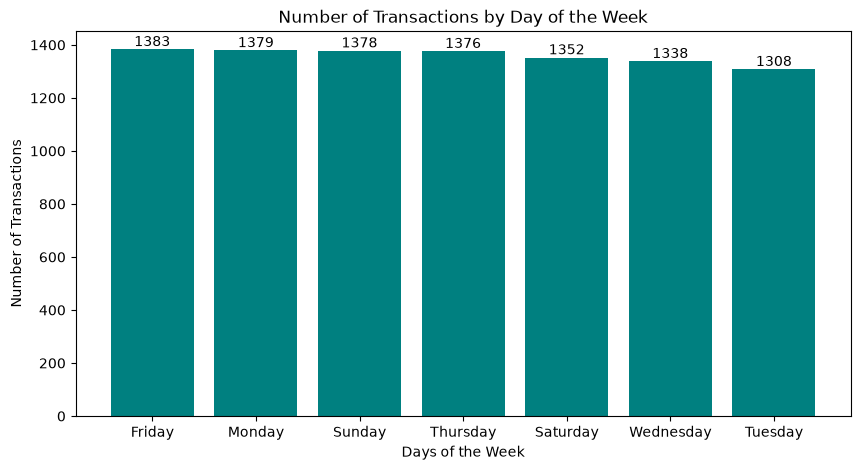

In [144]:
plt.figure(figsize = (10,5))
bars = plt.bar(day_weeks.index, day_weeks.values,color = 'teal')
plt.bar_label(bars) 
plt.xlabel('Days of the Week')
plt.ylabel('Number of Transactions')
plt.title('Number of Transactions by Day of the Week')
plt.show()

##### 4.3.2 Service-Type Transaction Distribution

Question: Which service type records the highest number of transactions?

In [145]:
Location_transaction_counts = eda_df[eda_df['Location'] != 'UNKNOWN']['Location'].value_counts().sort_values(ascending=False) 
Location_transaction_counts

Location
Takeaway    3016
In-store    3006
Name: count, dtype: int64

**Finding: Service-Type Transaction Distribution**

Among transactions with known location data, Takeaway recorded the highest number of transactions (3,016), while In-store recorded 3,006 transactions. The difference was only 10 transactions, indicating nearly equal usage of both service types.

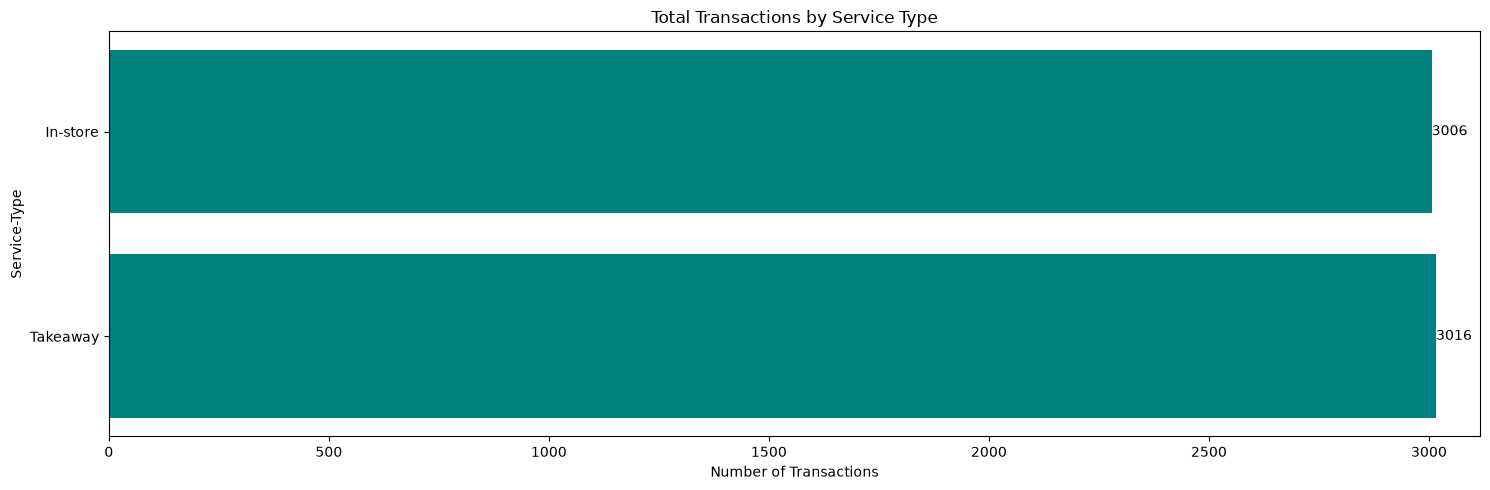

In [146]:
plt.figure(figsize = (15,5))
bars = plt.barh(Location_transaction_counts.index,Location_transaction_counts.values,color = 'teal')
plt.bar_label(bars, fmt = '%.0f')
plt.xlim(0, Location_transaction_counts. max()+ 100)
plt.xlabel('Number of Transactions')
plt.ylabel('Service-Type')
plt.title('Total Transactions by Service Type')
plt.tight_layout()
plt.show()


In [147]:
eda_df['Transaction Date'].dtype

<StringDtype(storage='python', na_value=nan)>

In [148]:
eda_df['Transaction Date'] = pd.to_datetime(
    eda_df['Transaction Date'],
    errors='coerce'
)

In [149]:
eda_df['Transaction Date'].dtype

dtype('<M8[us]')

## 5. Time-Based Analysis

### 5.1 Monthly Revenue Analysis

**Question:** How much revenue did the cafe generate in each month?


In [150]:
eda_df.groupby('Transaction Month')['Total Spent'].sum().sort_values(ascending = False)

Transaction Month
June         7353.0
October      7314.0
January      7254.0
March        7216.0
April        7179.0
December     7168.0
August       7092.5
November     6967.0
May          6932.5
July         6877.5
September    6871.0
February     6644.0
Name: Total Spent, dtype: float64

In [151]:
month_order = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]

monthly_spent = (
    eda_df.groupby('Transaction Month')['Total Spent']
    .sum()
    .reindex(month_order, fill_value=0)
)

monthly_spent

Transaction Month
January      7254.0
February     6644.0
March        7216.0
April        7179.0
May          6932.5
June         7353.0
July         6877.5
August       7092.5
September    6871.0
October      7314.0
November     6967.0
December     7168.0
Name: Total Spent, dtype: float64

June generated the highest monthly revenue (₹7,353), followed by October (₹7,314), while February recorded the lowest revenue (₹6,644). Monthly revenue fluctuated throughout the year, with a difference of ₹709 between the highest and lowest months. No consistent upward or downward trend was observed.

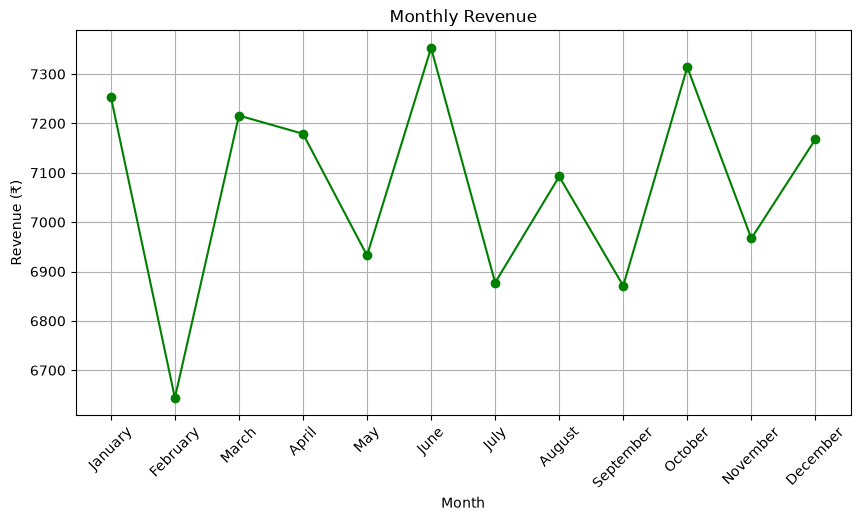

In [152]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_spent.index, monthly_spent.values, marker='o',color='green')
plt.title('Monthly Revenue')
plt.xlabel('Month')
plt.ylabel('Revenue (₹)')
plt.xticks(rotation=45)
plt.grid()
plt.show()

### 5.2 Weekday Revenue Analysis

**Question:** Which day of the week generates the highest total revenue?


In [153]:
#day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
week_day = eda_df.groupby('Day of the Week')['Total Spent'].sum().sort_values(ascending=False)
week_day

Day of the Week
Thursday     12401.5
Friday       12334.0
Sunday       12287.5
Monday       12140.0
Tuesday      12039.5
Saturday     11994.5
Wednesday    11671.5
Name: Total Spent, dtype: float64

Thursday generated the highest revenue (₹12,401.50), followed by Friday (₹12,334), while Wednesday recorded the lowest revenue (₹11,671.50). The difference between the highest and lowest weekday revenue was ₹730, indicating relatively small variations in revenue across weekdays.

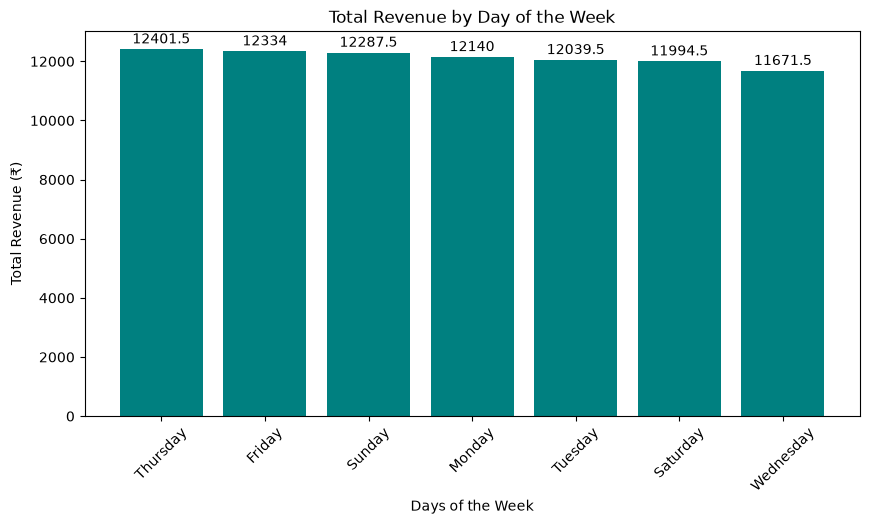

In [154]:
plt.figure(figsize = (10,5))
bars =plt.bar(week_day.index,week_day.values,color = 'teal')
ax = plt.gca()
ax.bar_label(bars,padding = 2)
plt.title('Total Revenue by Day of the Week')
plt.xlabel('Days of the Week')
plt.ylabel('Total Revenue (₹)')
plt.xticks(rotation=45)
plt.show()

### 5.3 Monthly Average Transaction Value

**Question:** Which month has the highest average transaction value?


In [155]:
monthly_avg= eda_df.groupby('Transaction Month')['Total Spent'].mean().sort_values(ascending=False)
monthly_avg

Transaction Month
April        9.311284
February     9.151515
December     9.073418
June         9.000000
May          8.979922
January      8.900613
November     8.886480
August       8.854557
September    8.741730
October      8.738351
March        8.736077
July         8.716730
Name: Total Spent, dtype: float64

April recorded the highest average transaction value at approximately ₹9.31, followed by February at ₹9.15. July had the lowest average transaction value at approximately ₹8.72. The difference between the highest and lowest monthly averages was approximately ₹0.59, indicating relatively small variations in average spending across months.

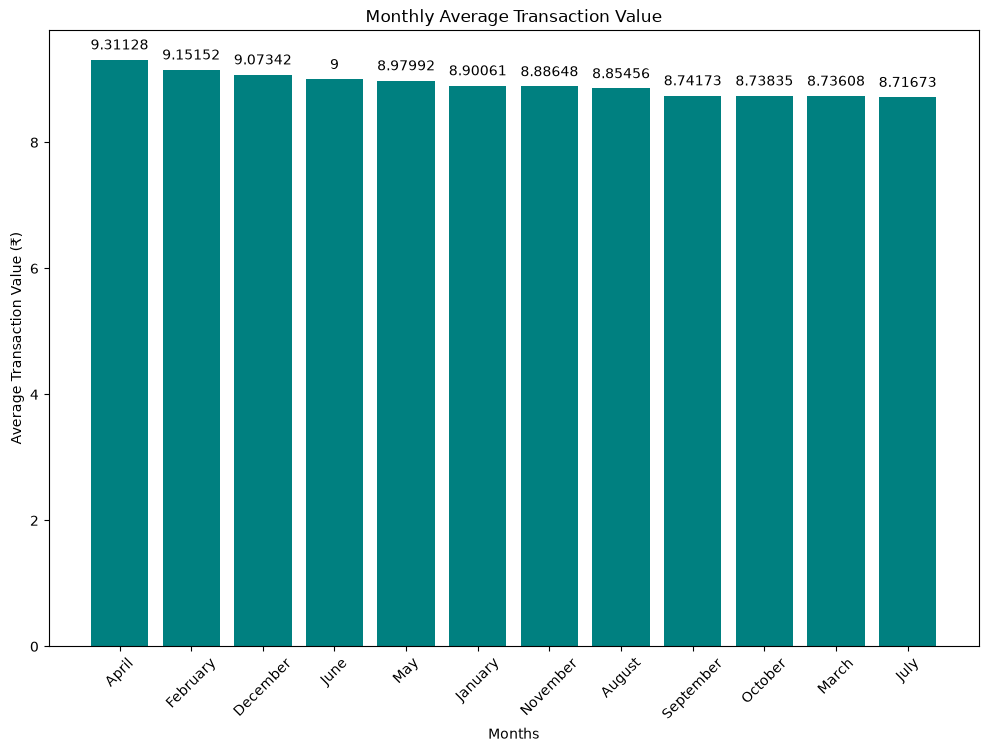

In [156]:
plt.figure(figsize= (12,8))
bars = plt.bar(monthly_avg.index,monthly_avg.values,color="teal")
ax = plt.gca()
ax.bar_label(bars,padding = 5)
plt.title('Monthly Average Transaction Value')
plt.xlabel('Months')
plt.ylabel('Average Transaction Value (₹)')
plt.xticks(rotation = 45)
plt.show()

### 5.4 Average Transaction Value by Weekday

**Question:** Which weekday has the highest average transaction value?


In [157]:
week_day_avg = eda_df.groupby('Day of the Week')['Total Spent'].mean().sort_values(ascending= False)
week_day_avg

Day of the Week
Tuesday      9.204511
Thursday     9.012718
Friday       8.918294
Sunday       8.916909
Saturday     8.871672
Monday       8.803481
Wednesday    8.723094
Name: Total Spent, dtype: float64

Tuesday recorded the highest average transaction value at approximately ₹9.20, while Wednesday had the lowest at approximately ₹8.72. Thursday, despite generating the highest total weekday revenue, ranked second in average transaction value. This highlights the difference between total revenue and average spending per transaction.

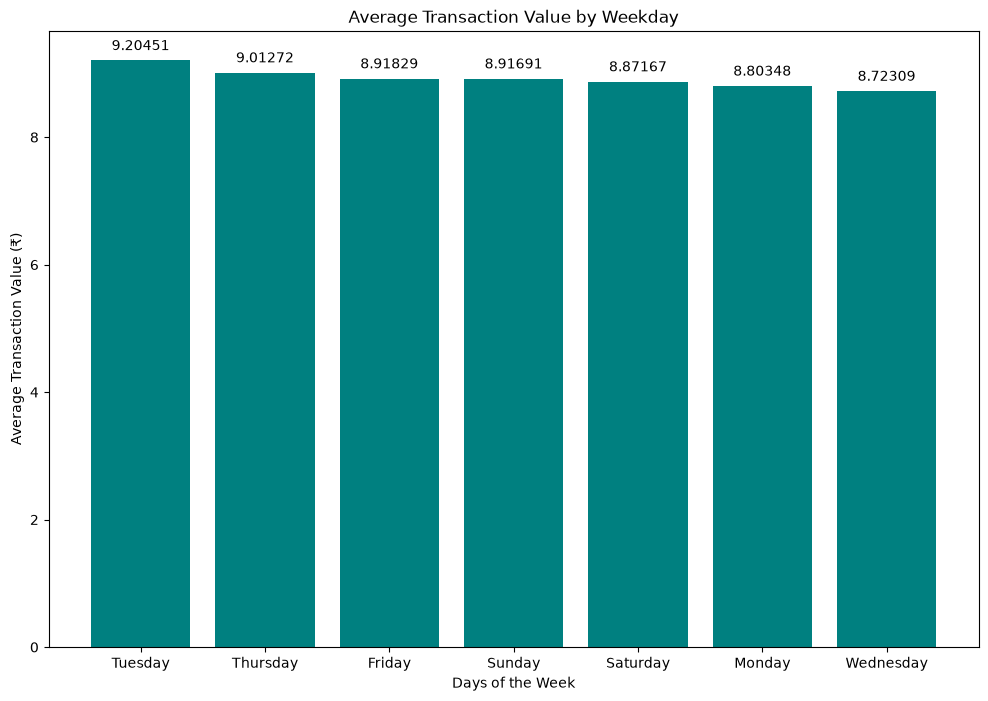

In [158]:
plt.figure(figsize = (12,8))
bars = plt.bar(week_day_avg.index,week_day_avg.values,color = "teal")
ax = plt.gca()
ax.bar_label(bars, padding = 5)
plt.title('Average Transaction Value by Weekday')
plt.xlabel('Days of the Week')
plt.ylabel('Average Transaction Value (₹)')
plt.show()

### 5.5 Monthly Transaction Volume

**Question:** Which month has the highest number of transactions, and how does transaction volume vary across the months?


In [159]:
month_order = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]
total_orders_montly = eda_df.groupby('Transaction Month')['Transaction ID'].count().reindex(month_order,fill_value = 0)
total_orders_montly

Transaction Month
January      815
February     726
March        826
April        771
May          772
June         817
July         789
August       801
September    786
October      837
November     784
December     790
Name: Transaction ID, dtype: int64

October recorded the highest transaction volume with 837 transactions, followed by March with 826 transactions. February had the lowest transaction volume, with 726 transactions. The difference between the highest and lowest months was 111 transactions.

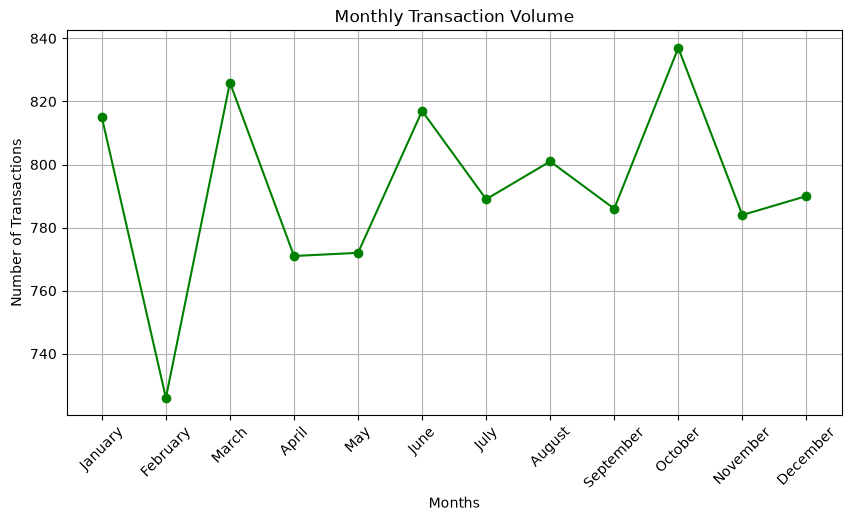

In [160]:
plt.figure(figsize = (10,5))
plt.plot(total_orders_montly.index,total_orders_montly.values,marker = 'o',color = 'green')
plt.xticks(rotation = 45)
plt.grid()
plt.title('Monthly Transaction Volume')
plt.xlabel('Months')
plt.ylabel('Number of Transactions')
plt.show()


### 5.6 Monthly Revenue vs. Transaction Volume

**Question:** Do months with a higher number of transactions also generate higher total revenue, or do the two metrics follow different patterns?


In [161]:
month_order = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]

monthly_spent = (
    eda_df.groupby('Transaction Month')['Total Spent']
    .sum()
    .reindex(month_order, fill_value=0)
)

monthly_count = eda_df.groupby('Transaction Month')['Transaction ID'].count().reindex(month_order,fill_value = 0)
total_matrix = pd.concat([monthly_count,monthly_spent],axis=1)
total_matrix

,Transaction ID,Total Spent
Transaction Month,,
January,815,7254.0
February,726,6644.0
March,826,7216.0
April,771,7179.0
May,772,6932.5
June,817,7353.0
July,789,6877.5
August,801,7092.5
September,786,6871.0


The comparison shows that months with a higher number of transactions do not necessarily generate higher total revenue. For example, October recorded the highest transaction volume (837 transactions), but its revenue (₹7,314) was lower than June's revenue (₹7,353), even though June had only 817 transactions. Similarly, March recorded 826 transactions but generated ₹7,216, which was also lower than June's revenue. This indicates that transaction volume and total revenue do not always follow the same pattern.

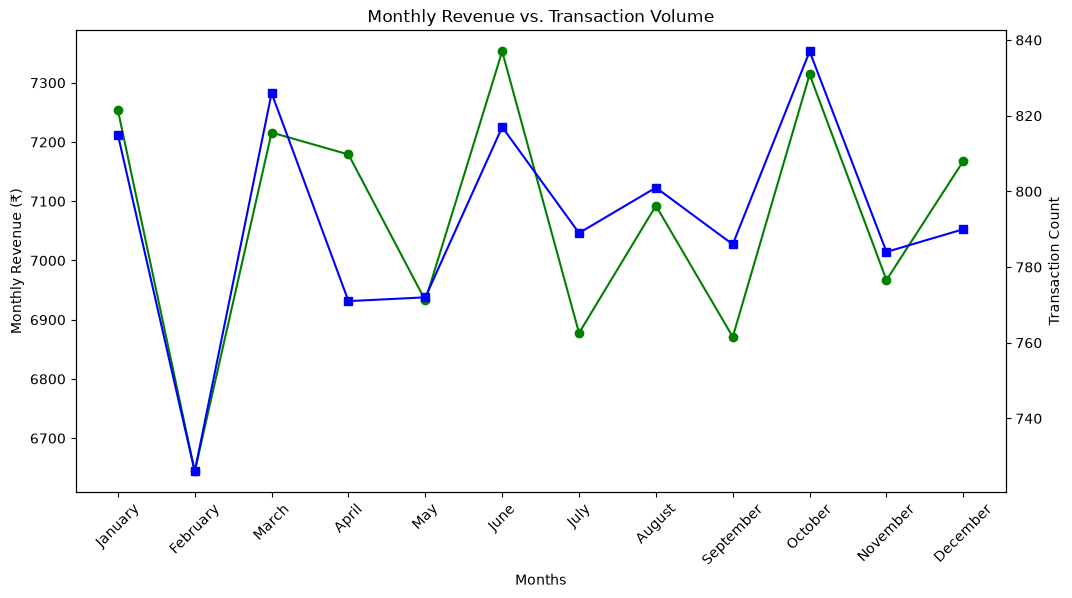

In [162]:
fig, ax1 = plt.subplots(figsize=(12, 6))
ax2 = ax1.twinx()
ax1.plot(monthly_spent.index, monthly_spent.values,color = 'green',marker='o') 
ax2.plot(monthly_count.index,monthly_count.values,color = 'blue',marker = 's')
ax1.set_ylabel('Monthly Revenue (₹)')
ax2.set_ylabel('Transaction Count')
ax1.set_xlabel('Months')
ax1.set_xticks(range(len(month_order)))
ax1.set_xticklabels(month_order,rotation = 45)
plt.title('Monthly Revenue vs. Transaction Volume')
plt.show()


### 5.7 Average Daily Revenue by Month

**Question:** How does the average revenue generated per day vary across different months, and which month has the highest average daily revenue?


In [163]:
daily_revenue = (
    eda_df.groupby('Transaction Date')['Total Spent']
    .sum()
)

monthly_avg_daily_revenue = (
    daily_revenue.groupby(daily_revenue.index.month_name())
    .mean()
    .reindex(month_order)
)

monthly_avg_daily_revenue

Transaction Date
January      234.000000
February     237.285714
March        232.774194
April        239.300000
May          223.629032
June         245.100000
July         221.854839
August       228.790323
September    229.033333
October      235.935484
November     232.233333
December     231.225806
Name: Total Spent, dtype: float64

June recorded the highest average daily revenue at approximately ₹245.10, followed by April at ₹239.30. July had the lowest average daily revenue at approximately ₹221.85. The difference between the highest and lowest monthly averages was approximately ₹23.25 per day. June's higher average daily revenue is consistent with its position as the highest revenue-generating month overall.

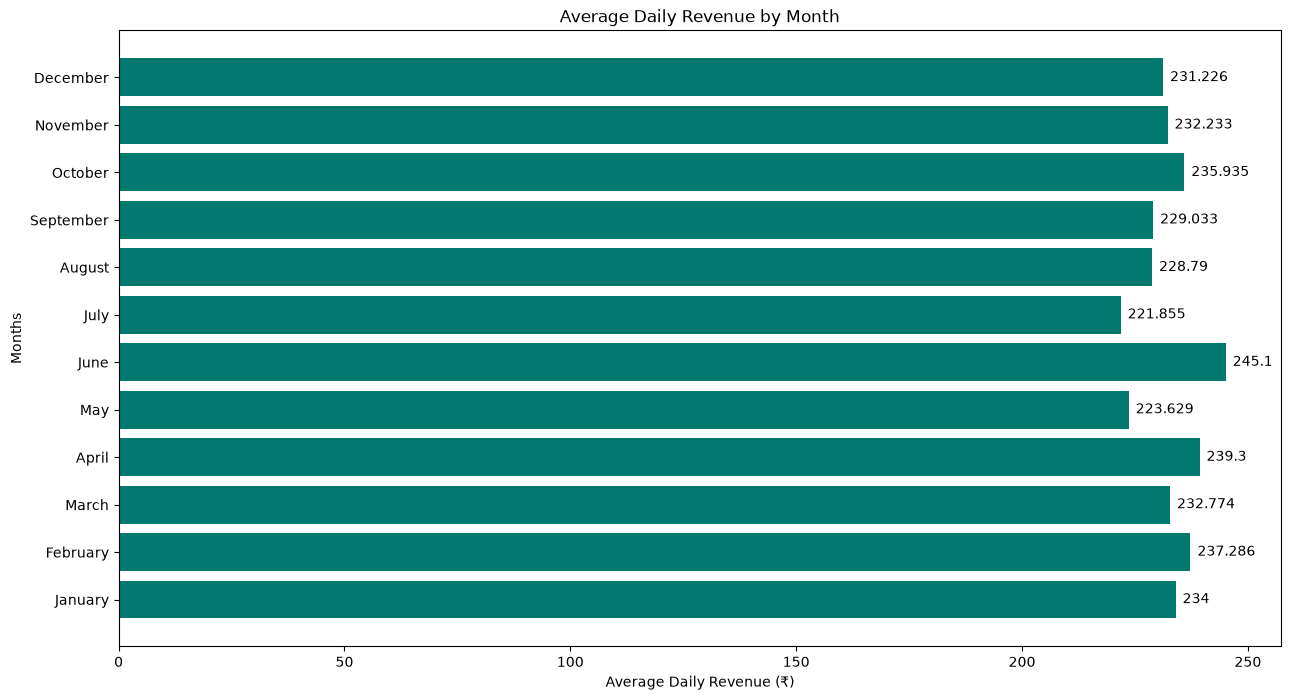

In [164]:
plt.figure(figsize = (15,8))
bars = plt.barh(monthly_avg_daily_revenue.index, monthly_avg_daily_revenue.values, color = "#01796F")
plt.xlabel('Average Daily Revenue (₹)')
plt.ylabel('Months')
ax = plt.gca()
ax.bar_label(bars,padding = 5)
plt.title('Average Daily Revenue by Month')
plt.show()

### 5.8 Monthly Average Quantity

**Question:** Which month has the highest average purchase quantity, and how does the average quantity of items purchased vary across different months?


In [165]:
montly_avg_quantity = eda_df[eda_df['Item'] != 'UNKNOWN'].groupby('Transaction Month')['Quantity'].mean().reindex(month_order,fill_value = 0)
montly_avg_quantity

Transaction Month
January      3.002554
February     3.090247
March        2.993711
April        3.062756
May          3.009524
June         3.011658
July         2.952632
August       3.011968
September    2.994638
October      3.048447
November     2.982759
December     3.067385
Name: Quantity, dtype: float64

February recorded the highest average purchase quantity at approximately 3.09 units per transaction, followed by December at 3.07 units. July had the lowest average purchase quantity at approximately 2.95 units. The difference between the highest and lowest monthly averages was approximately 0.14 units, indicating that the average purchase quantity remained relatively consistent throughout the year.

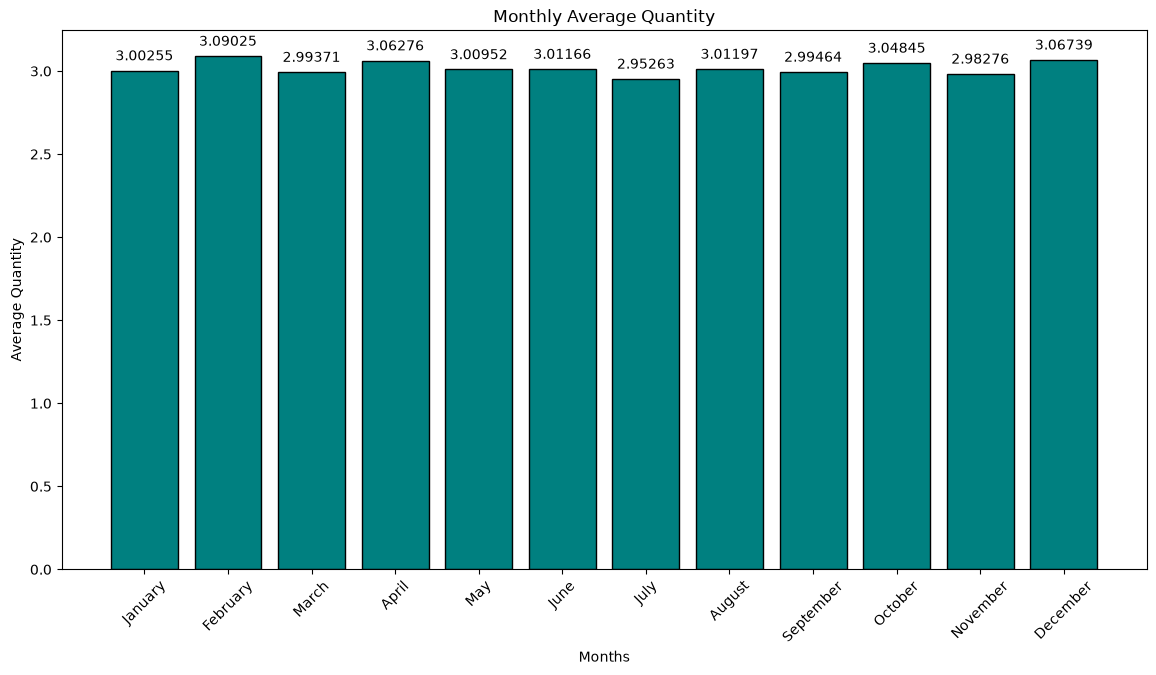

In [166]:
plt.figure(figsize = (14,7))
bars = plt.bar(montly_avg_quantity.index, montly_avg_quantity.values, color="teal", edgecolor='black')
ax = plt.gca()
ax.bar_label(bars,padding = 5)
plt.title('Monthly Average Quantity')
plt.xlabel('Months')
plt.ylabel('Average Quantity')
plt.xticks(rotation = 45)
plt.show()


### 5.9 Monthly Product Performance

**Question:** Which product generates the highest revenue in each month, and does the best-performing product remain consistent throughout the year?


In [167]:
main_mat = eda_df[eda_df['Item'] != 'UNKNOWN'].groupby(['Transaction Month','Item'])['Total Spent'].sum() 

In [168]:
month_topRevenue = main_mat.groupby(level = 0).max()

In [169]:
tans_month_list = main_mat.groupby(level = 0).idxmax()

In [170]:
trans_mon = pd.DataFrame({
    'Top_Product': tans_month_list.map(lambda x:x[1]),  #monthly_top_product.map(lambda x: x[1])
    'Revenue': month_topRevenue
}).reindex(month_order) 

In [171]:
trans_mon

,Top_Product,Revenue
Transaction Month,,
January,Salad,1665.0
February,Salad,1330.0
March,Salad,1560.0
April,Salad,1610.0
May,Salad,1370.0
June,Salad,1645.0
July,Salad,1715.0
August,Salad,1580.0
September,Salad,1245.0


**Findings:**

Salad consistently generated the highest revenue among all known products across all 12 months. July recorded the highest monthly revenue from Salad at ₹1,715, while September recorded the lowest at ₹1,245. This indicates that Salad was the top revenue-generating product throughout the year, although its monthly revenue varied.

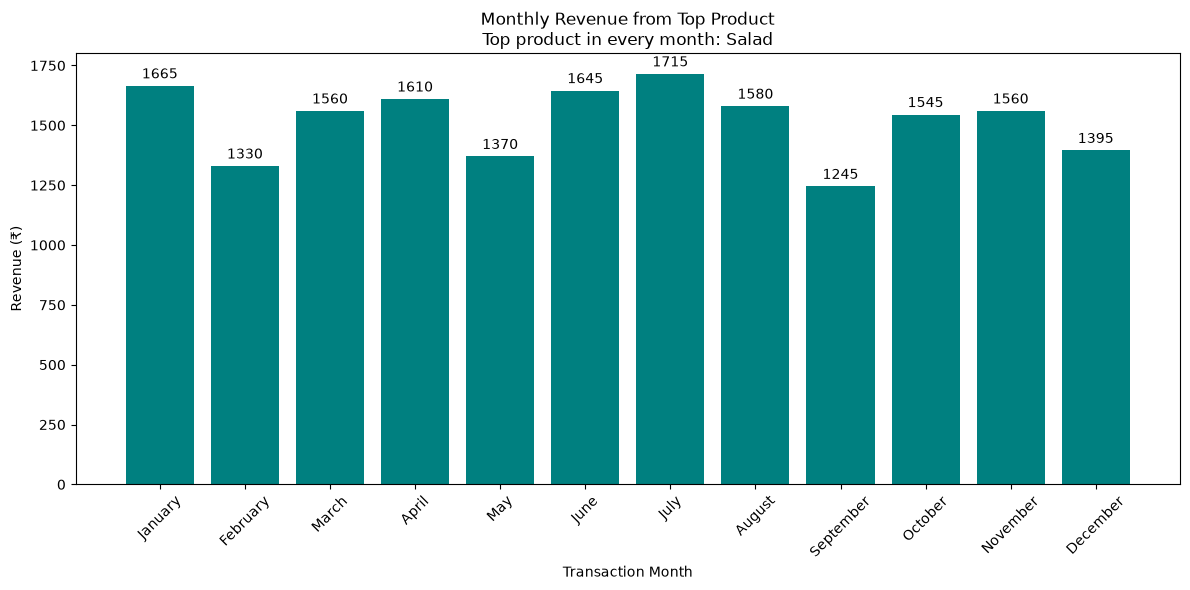

In [172]:
#import matplotlib.pyplot as plt

# Replace monthly_top_product with the name of your DataFrame
data = trans_mon 
fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(data.index, data["Revenue"], color="teal")
ax.bar_label(bars, fmt="%.0f", padding=3)

ax.set_title("Monthly Revenue from Top Product\nTop product in every month: Salad")
ax.set_xlabel("Transaction Month")
ax.set_ylabel("Revenue (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6. Service-Type Analysis

**Question:** Which service type generates the highest total revenue: Takeaway or In-store?


In [173]:
location_spent = eda_df[eda_df['Location'] != 'UNKNOWN'].groupby('Location')['Total Spent'].sum()
location_spent

Location
In-store    27140.0
Takeaway    26552.5
Name: Total Spent, dtype: float64

In-store generated the highest total revenue of ₹27,140, compared to Takeaway at ₹26,552.50. The difference was ₹587.50.

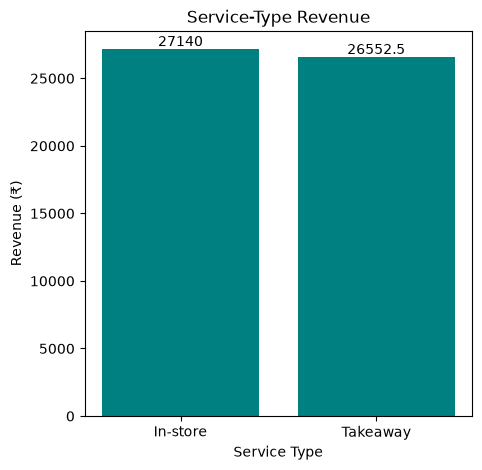

In [174]:
plt.figure(figsize = (5,5))
bars = plt.bar(location_spent.index,location_spent.values,color = 'teal')
ax = plt.gca()
ax.bar_label(bars)
plt.xlabel('Service Type')
plt.ylabel('Revenue (₹)')
plt.title('Service-Type Revenue') 
plt.show()

Does the average transaction value differ between Takeaway and In-store orders?

In [175]:
service_avg = eda_df[eda_df['Location'] != 'UNKNOWN'].groupby('Location')['Total Spent'].mean()
service_avg

Location
In-store    9.028609
Takeaway    8.803879
Name: Total Spent, dtype: float64

In-store orders had a slightly higher average transaction value (₹9.03) than Takeaway orders (₹8.80), a difference of approximately ₹0.22.

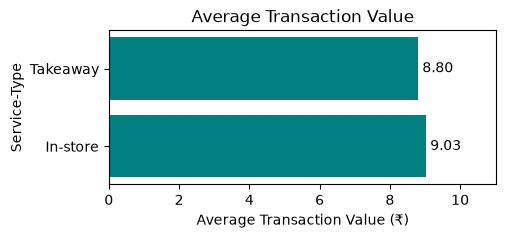

In [176]:
plt.figure(figsize = (5,2))
bars = plt.barh(service_avg.index,service_avg.values, color="teal") 
plt.bar_label(bars, fmt="%.2f", padding=3) 
plt.xlim(0, service_avg.max() + 2)
plt.xlabel('Average Transaction Value (₹)')
plt.ylabel('Service-Type')
plt.title('Average Transaction Value') 
plt.show()
